# 05 Hierarchical clustering

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style='whitegrid')

In [2]:
data = pd.read_csv('../data/processed/kmeans_clusters.csv')
raw = pd.read_csv('../data/processed/countries_2019.csv')
names = ['GDP_PC', 'GDP_GROWTH', 'INFLATION', 'UNEMPLOYMENT', 'TRADE', 'CAPITAL_FORMATION',
         'LIFE_EXPECTANCY', 'URBAN_POP', 'INTERNET_USERS', 'ELECTRICITY_ACCESS', 'SECONDARY_ENROLLMENT']
income_order = ['Low income', 'Lower middle income', 'Upper middle income', 'High income']
order = ['Low development', 'Stagnating, high unemployment', 'Dynamic emerging', 'High development']
X = data[names].values

def agreement(labels_a, labels_b):
    table = pd.crosstab(labels_a, labels_b)
    a_to_b = table.max(axis=1).sum()
    b_to_a = table.max(axis=0).sum()
    return min(a_to_b, b_to_a) / len(labels_a)

## Dendrogram (Ward linkage)

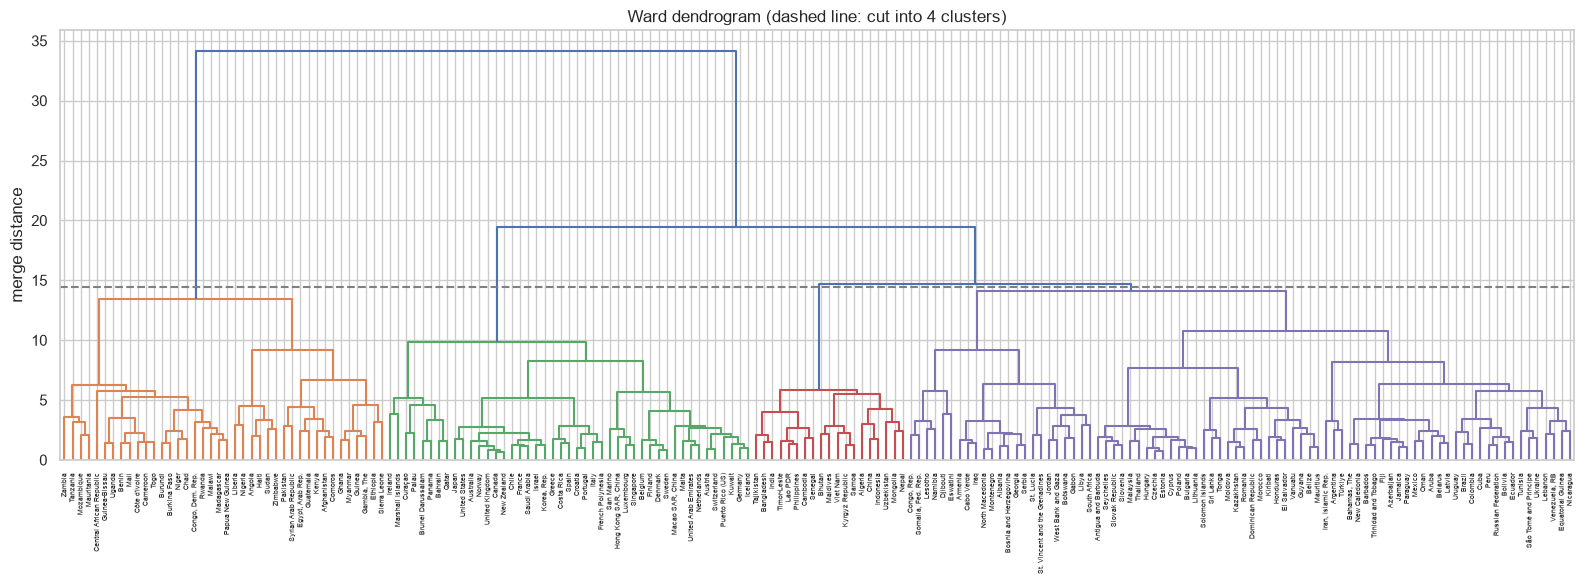

In [3]:
Z_ward = linkage(X, method='ward')
cut = (Z_ward[-4, 2] + Z_ward[-3, 2]) / 2
plt.figure(figsize=(16, 6))
dendrogram(Z_ward, labels=list(data['country']), leaf_font_size=5, color_threshold=cut)
plt.axhline(cut, color='grey', linestyle='--')
plt.title('Ward dendrogram (dashed line: cut into 4 clusters)')
plt.ylabel('merge distance')
plt.tight_layout()
plt.savefig('../figures/05_dendrogram_ward.png', dpi=200)
plt.show()

## Number of clusters

In [4]:
for k in range(2, 9):
    labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)
    print(f'K = {k}: silhouette = {silhouette_score(X, labels):.3f}')

K = 2: silhouette = 0.319
K = 3: silhouette = 0.143
K = 4: silhouette = 0.127
K = 5: silhouette = 0.133
K = 6: silhouette = 0.143
K = 7: silhouette = 0.130
K = 8: silhouette = 0.138


## Linkage methods (K = 4)

In [5]:
results = []
for method in ['ward', 'complete', 'average']:
    labels = AgglomerativeClustering(n_clusters=4, linkage=method).fit_predict(X)
    data[method] = labels
    sizes = list(pd.Series(labels).value_counts())
    results.append([method, sizes, silhouette_score(X, labels), agreement(data['cluster'], labels)])
pd.DataFrame(results, columns=['linkage', 'cluster sizes', 'silhouette', 'agreement with K-means']).round(3)

,linkage,cluster sizes,silhouette,agreement with K-means
0,ward,"[82, 45, 40, 19]",0.127,0.677
1,complete,"[94, 44, 42, 6]",0.168,0.742
2,average,"[174, 9, 2, 1]",0.155,0.398


In [6]:
pd.crosstab(data['cluster_name'], data['complete']).loc[order]

complete,0,1,2,3
cluster_name,,,,
Low development,33,0,0,1
"Stagnating, high unemployment",7,17,6,0
Dynamic emerging,2,15,0,37
High development,0,62,0,6


In [7]:
pd.crosstab(data['cluster_name'], data['average']).loc[order]

average,0,1,2,3
cluster_name,,,,
Low development,29,0,4,1
"Stagnating, high unemployment",25,0,5,0
Dynamic emerging,53,1,0,0
High development,67,1,0,0


## Ward clusters vs K-means

In [8]:
means = data.groupby('ward')['GDP_PC'].mean().sort_values()
new_label = {}
for i, old in enumerate(means.index):
    new_label[old] = i
data['ward'] = data['ward'].map(new_label)
raw['ward'] = data['ward']

ward_vs_kmeans = pd.crosstab(data['cluster_name'], data['ward']).loc[order]
ward_vs_kmeans

ward,0,1,2,3
cluster_name,,,,
Low development,33,1,0,0
"Stagnating, high unemployment",5,0,25,0
Dynamic emerging,2,18,32,2
High development,0,0,25,43


In [9]:
profile = raw.groupby('ward')[names].median().T
profile.loc['countries'] = raw['ward'].value_counts()
profile.round(1)

ward,0,1,2,3
GDP_PC,1001.6,2589.3,6821.0,43160.7
GDP_GROWTH,4.7,6.1,2.2,2.0
INFLATION,3.9,2.8,2.3,1.1
UNEMPLOYMENT,4.2,4.6,8.1,5.0
TRADE,46.7,66.5,86.6,90.0
CAPITAL_FORMATION,22.0,34.1,22.1,23.9
LIFE_EXPECTANCY,62.9,71.0,74.2,82.1
URBAN_POP,36.6,39.6,65.0,83.6
INTERNET_USERS,19.2,49.4,69.9,89.7
ELECTRICITY_ACCESS,45.5,98.9,99.9,100.0


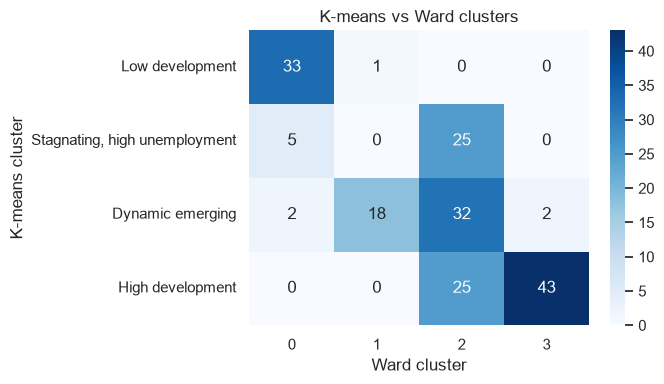

In [10]:
plt.figure(figsize=(7, 4))
sns.heatmap(ward_vs_kmeans, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Ward cluster')
plt.ylabel('K-means cluster')
plt.title('K-means vs Ward clusters')
plt.tight_layout()
plt.savefig('../figures/05_kmeans_vs_ward.png', dpi=200)
plt.show()

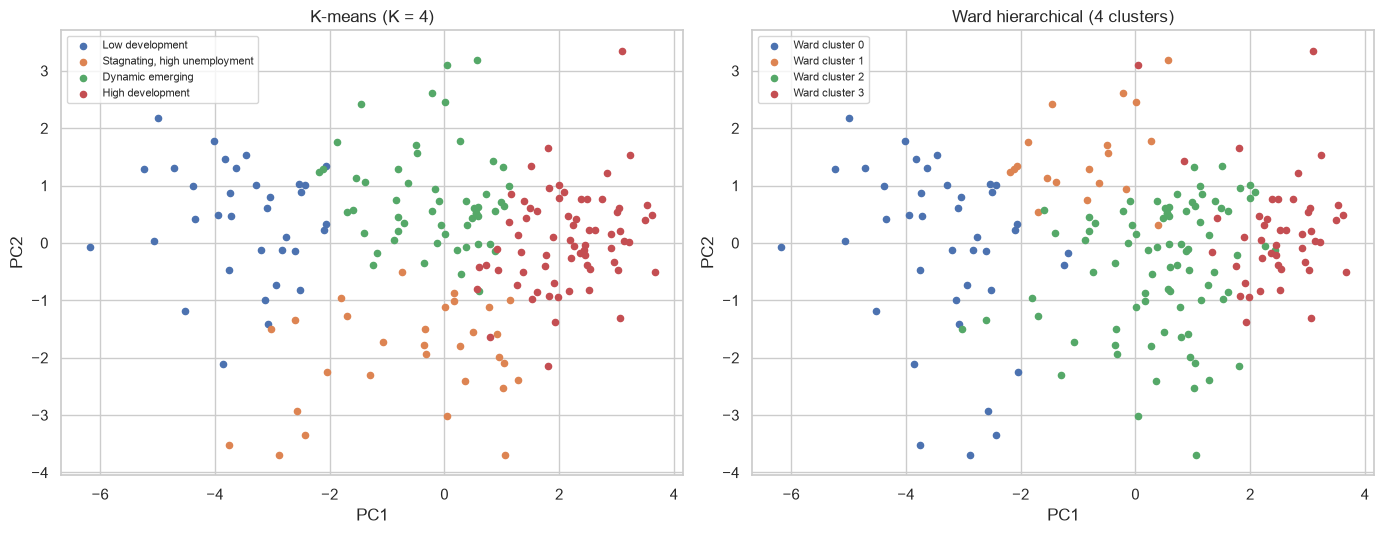

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name in order:
    part = data[data['cluster_name'] == name]
    axes[0].scatter(part['PC1'], part['PC2'], s=20, label=name)
for k in range(4):
    part = data[data['ward'] == k]
    axes[1].scatter(part['PC1'], part['PC2'], s=20, label=f'Ward cluster {k}')
axes[0].set_title('K-means (K = 4)')
axes[1].set_title('Ward hierarchical (4 clusters)')
for ax in axes:
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('../figures/05_kmeans_ward_pca.png', dpi=200)
plt.show()

## Ward clusters vs income groups

In [12]:
pd.crosstab(data['ward'], data['income_group'])[income_order]

income_group,Low income,Lower middle income,Upper middle income,High income
ward,,,,
0,20,19,1,0
1,0,11,8,0
2,1,17,42,22
3,0,0,1,44


## Countries placed differently

In [13]:
for name in order:
    part = data[data['cluster_name'] == name]
    main_ward = part['ward'].value_counts().index[0]
    moved = part[part['ward'] != main_ward]
    print(name, '-> mostly Ward cluster', main_ward)
    print('   placed elsewhere:', list(moved['country']))

Low development -> mostly Ward cluster 0
   placed elsewhere: ['Senegal']
Stagnating, high unemployment -> mostly Ward cluster 2
   placed elsewhere: ['Angola', 'Haiti', 'Sudan', 'Syrian Arab Republic', 'Zimbabwe']
Dynamic emerging -> mostly Ward cluster 2
   placed elsewhere: ['Bangladesh', 'Bhutan', 'China', 'Algeria', 'Egypt, Arab Rep.', 'Guatemala', 'Indonesia', 'India', 'Kyrgyz Republic', 'Cambodia', 'Lao PDR', 'Maldives', 'Marshall Islands', 'Mongolia', 'Nepal', 'Panama', 'Philippines', 'Tajikistan', 'Timor-Leste', 'Uzbekistan', 'Viet Nam', 'Samoa']
High development -> mostly Ward cluster 3
   placed elsewhere: ['Aruba', 'Bulgaria', 'Bahamas, The', 'Belarus', 'Barbados', 'Cuba', 'Cyprus', 'Czechia', 'Ecuador', 'Estonia', 'Hungary', 'Lithuania', 'Latvia', 'Mexico', 'Malaysia', 'New Caledonia', 'Oman', 'Peru', 'Poland', 'Paraguay', 'Russian Federation', 'Slovak Republic', 'Slovenia', 'Trinidad and Tobago', 'Uruguay']


## Save

In [14]:
data.to_csv('../data/processed/all_clusters.csv', index=False)